# 2. Random Forests for Image Approximation: Mona Lisa

## a. Read and Display Image

In [64]:
import numpy as np
from PIL import Image
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt
#import cv2

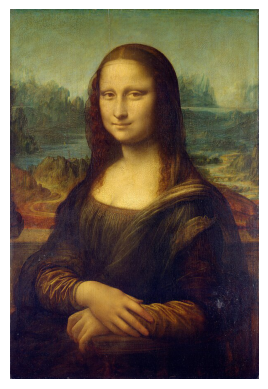

In [65]:
img = Image.open('mona_lisa.jpg')
plt.imshow(img)
plt.axis('off')
plt.show()

## b. Preprocessing the input

In [66]:
img_array = np.array(img)
height, width = img_array.shape[:2]
n_samples = 5000
x_coords = np.random.randint(0, width, n_samples)
y_coords = np.random.randint(0, height, n_samples)

## c. Preprocess the output

#### Option 1. img to grayscale

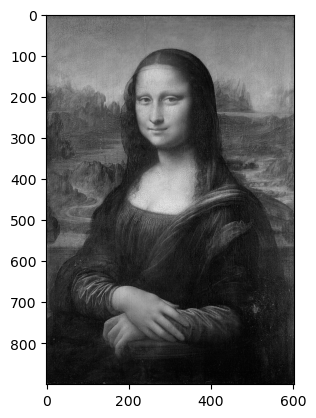

In [67]:
img_array = np.asarray(img)
gray = np.dot(img_array[...,:3], [0.2989, 0.5870, 0.1140])
plt.imshow(gray, cmap=plt.get_cmap("gray"))
plt.show()

#### Pre-processing steps performed:
- Normalize pixel values - rescale all points (currently from 0-255) on a scale of [0.0,1.0] for better regression by putting the variable on a standard scale.
- Normalize coordinate plane - rescale all x and y points on a scale of [0.0,1.0] because otherwise our y (being larger than our x) could potentially bias our dataset. By normalizing x and y to be the same range, that eliminates any bias towards the larger coordinate.
- Other standard pre-processing is not applicable here: our dataset has no missing values since we directly sampled pixel coordinates from the image and our data contains no inconsistencies or errors since it was generated programmatically from a clean source.

In [68]:
gray_normalized = gray / 255.0
y_train = gray_normalized[y_coords, x_coords]
x_normalized = x_coords / width
y_normalized = y_coords / height 

X_train = np.column_stack([x_normalized, y_normalized])  # Input features

## d. Build final image
References:
https://www.geeksforgeeks.org/machine-learning/random-forest-regression-in-python/
https://medium.com/@prathik.codes/mastering-randomforestregressor-in-scikit-learn-a-practical-guide-ba8615097100

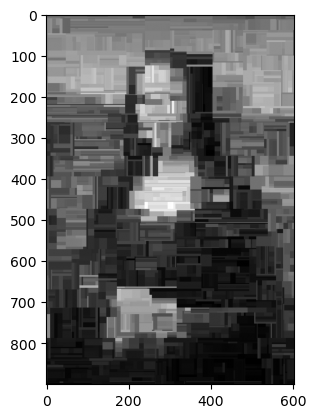

In [69]:
regressor = RandomForestRegressor(n_estimators=1, random_state=0)
regressor.fit(X_train, y_train)
coords = [(x/width, y/height) for y in range(height) for x in range(width)]
prediction = regressor.predict(coords)
reconstructed = prediction.reshape(height, width)
plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
plt.show()

## e. Experimentation

How does depth impact the result? Describe in detail why.

Depth is the amount of splits we can perform into the image space, for example with depth = 1, we just see a white block and a black block since there is only one split in the image space. As we increase depth, we increase the number of splits and the number of blocks in our outcome. With our highest depth of 15, we have 2^15 blocks so we end up with a very cubist interpretation of the Mona Lisa but closest resemblance to the actual painting. We see here with fewer splits of the coordinate plane, we are underfitting and ending up with completely abstracted gray blocks, but as we increase splits, we may be overfitting by over learning splits in the data while we would be more productive in tuning other hyperparameters instead. Each split is colored with the average value of training samples in that region. This means with fewer splits, there are more samples in a rectangular region which leads to an average value that is not representative of the variation in values. This is why in our first image, with just one split, we end up with a white and a black rectange since each contains about 2500 samples averaged, which loses all complexity and variation. Adding more splits by increasing the depth also therefore reduces the number of samples in each rectangle so allows for more differentiation in values between splits.

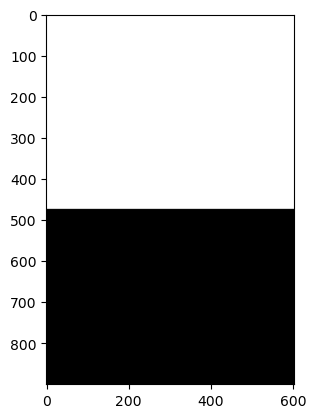

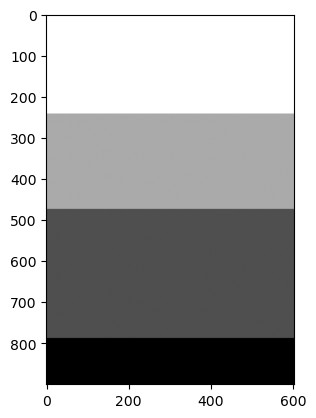

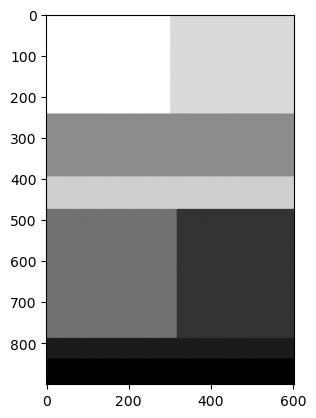

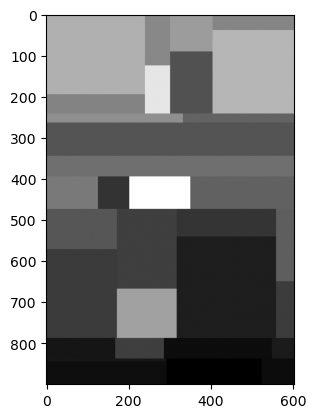

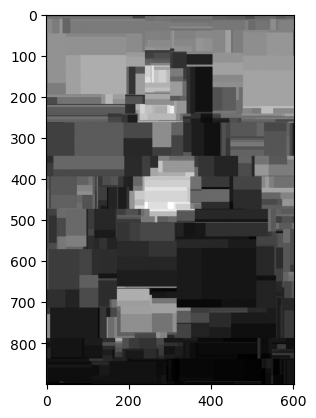

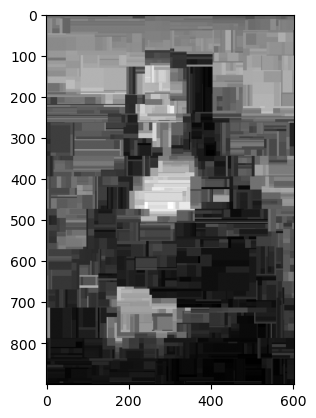

In [70]:
depths = [1,2,3,5,10,15]
for d in depths:
    regressor = RandomForestRegressor(n_estimators=1, max_depth = d, random_state=0)
    regressor.fit(X_train, y_train)
    prediction = regressor.predict(coords)
    reconstructed = prediction.reshape(height, width)
    plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
    plt.show()

How does the number of trees impact the result? Describe in detail
why. 

The number of trees visually seems to impact the boundaries between subdivided regions of the image plane. Since we were holding depth constant, we expect to see the same number of subdivided regions/i.e. gray color blocks in our final image, but as we increase the n_estimators (the number of trees) we see blurrier and blurrier divisions between the regions. Put more scientifically, each tree makes a decision at the split in which ties are broken randomly and the more trees we include, the more the ties are averaged which provides a more blurred as opposed to decisive boundary. Since trees can make mistakes, these harsh boundaries could be wrong so by including more trees and averaging, we get a less defined boundary which reduces variance and overfitting, since it reduces the impact of an error in a single tree.

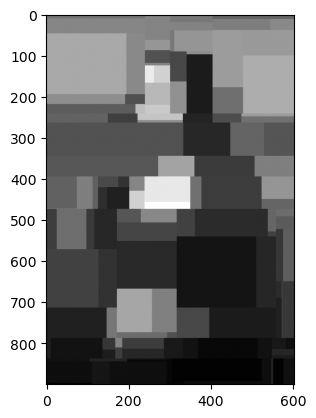

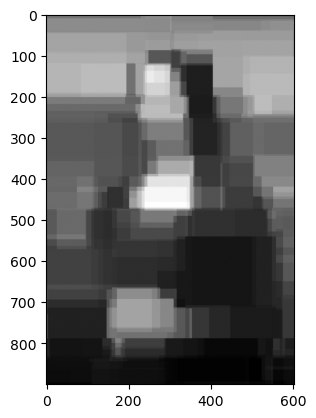

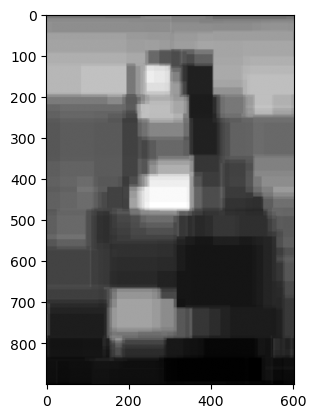

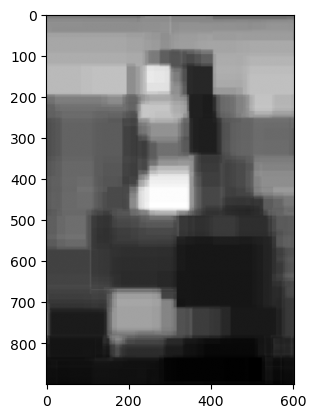

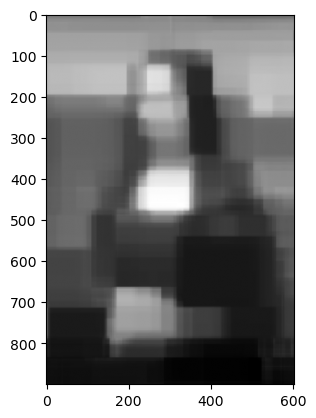

In [71]:
ntrees = [1,3,5,10,100]
for n in ntrees:
    regressor = RandomForestRegressor(n_estimators=n, max_depth = 7, random_state=0)
    regressor.fit(X_train, y_train)
    prediction = regressor.predict(coords)
    reconstructed = prediction.reshape(height, width)
    plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
    plt.show()

Compare and contrast the outlook: why does this look the way it does? 

While the previous Mona Lisas were cubist, this one is pointilist. Pixels that exist in the training set are exact and creates a little homogenous dot of color for all its surrounding pixels. Since we sampled 5000 points, we would expect our image to have about 5000 dots of color. This is because for every pixel, it looks for its nearest data point in the training set of 5000 and returns the same color. There can be sharp boundaries between these dots of color (like in her hairline) because the training points can change in value severely. This leads to sharp discontinuous boundaries as opposed to the extremely smooth boundaries we just found above with our increased number of trees. This results in a very discontinuous mosaic-ed end result. That being said, it is very clearly the Mona Lisa even if details are lost in the homogeny, particularly in the hands. Compared to our various Random Forest outputs, this algorithm doesn't learn and instead looks up data points in the training and directly copies them. This gives us a fairly accurate image of Mona Lisa without the smoothness of RF.


KNN implementation used: 
https://www.geeksforgeeks.org/machine-learning/k-nearest-neighbors-knn-regression-with-scikit-learn/

In [72]:
knn_regressor = KNeighborsRegressor(n_neighbors=1)
knn_regressor.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=1)

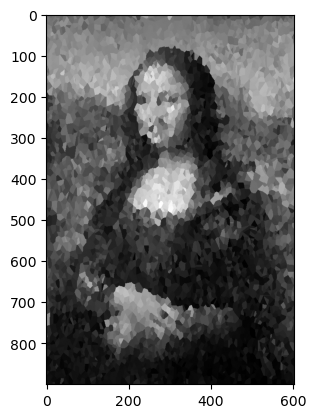

In [73]:
prediction = knn_regressor.predict(coords)
reconstructed = prediction.reshape(height, width)
plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
plt.show()

PRUNING STRATEGIES:
Here I implemented two pruning strategies, min_samples_leaf and min_samples_split. I performed a similar iteration to above where I tried multiple different values for each hyperparameter, holding max_depth constant at 7. With both parameters, I observed the resulting images looked mostly the same to each other for smaller values until I got to 100, at which point the image became noticeably blurrier. This occured likely because for each tree, there were many samples to choose from so putting a small floor on it did not substantially affect the options of the tree. However, when I put a higher floor like 100, then the trees were prevented from natural splits and we saw a decrease in quality of the decisions and the resulting image. This shows min_samples_leaf and min_samples_split are ineffective pruning strategies since they need to be very high to constrain the model and we had much more effective results with max_depth.

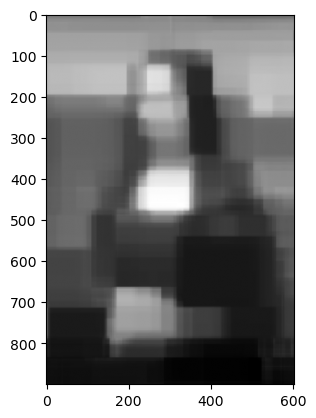

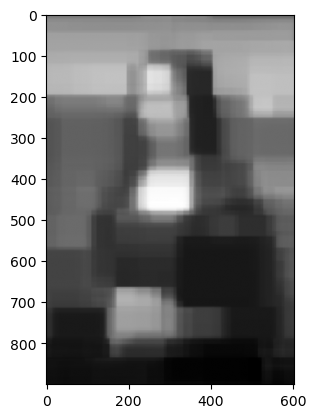

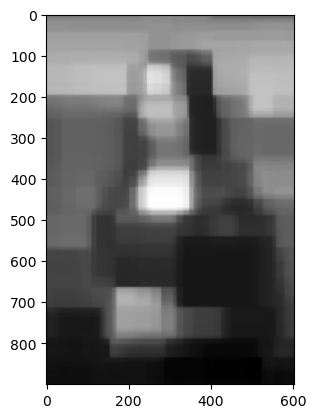

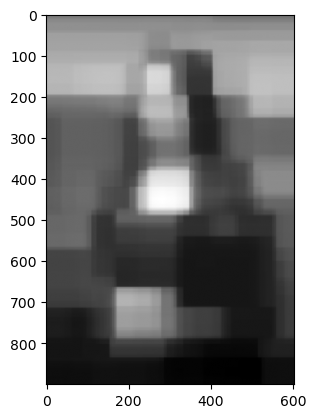

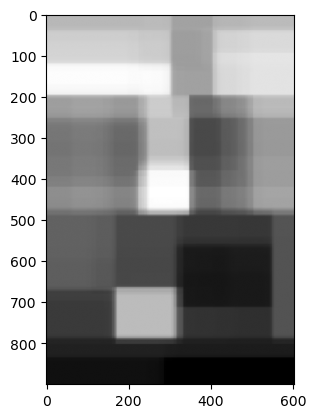

In [74]:
nsamples = [1,5,10,20,100]
for n in nsamples:
    regressor = RandomForestRegressor(min_samples_leaf = n, max_depth = 7, random_state=0)
    regressor.fit(X_train, y_train)
    prediction = regressor.predict(coords)
    reconstructed = prediction.reshape(height, width)
    plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
    plt.show()

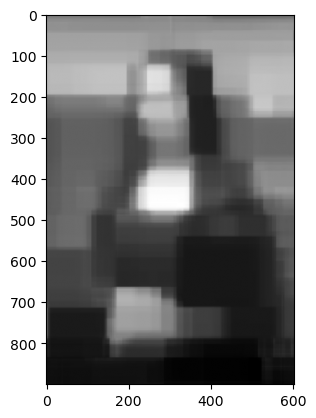

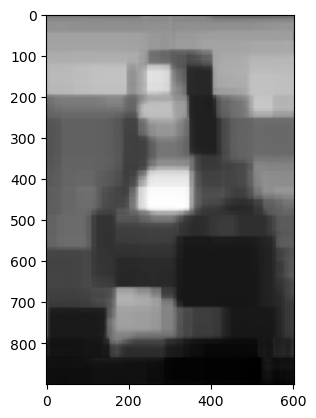

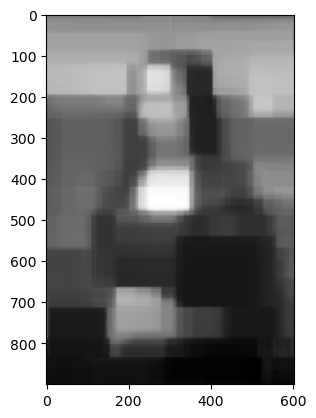

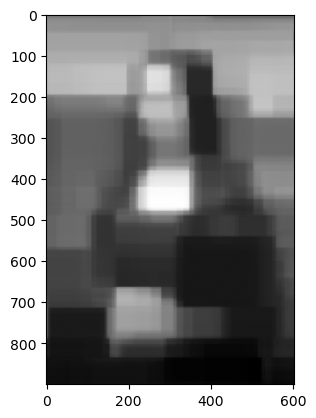

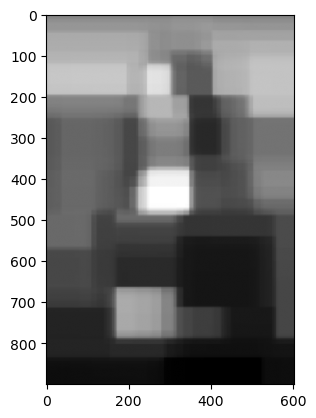

In [75]:
nsamples = [2,5,10,20,100]
for n in nsamples:
    regressor = RandomForestRegressor(min_samples_split = n, max_depth = 7, random_state=0)
    regressor.fit(X_train, y_train)
    prediction = regressor.predict(coords)
    reconstructed = prediction.reshape(height, width)
    plt.imshow(reconstructed, cmap=plt.get_cmap("gray"))
    plt.show()

## f. Analysis

i. The decision rule within the random forest as a general formula was: if feature <= threshold: go to left child; else: go to right child. Our features here were our X and Y coordinate. Defined a little more explicitly in pseudocode,

x = feature (x or y coordinate);
t = threshold for subdividing the image plane;
child_l = left child node (subtree);
child_r = right child node (subtree)

if x <= t:
    child_l;
else:
    child_r

ii. Our resulting image from step d. has a blcoky, rectangular appearance due to a combination of the various explanations we found above. We discovered in the experimentation that the cubist look of the final image was the result of decision trees splitting the image plane into smaller subdivisions and each smaller region created was then assigned the same value, representing the average brightness of training samples in that region. The image plane was subdivided into regions using decision trees making splits based on the coordinate values as defined just above in f.i. These regions are rectangular because each split is aligned along axes because of our features being our x and y coordinates, so each decision split includes all values of x less than 300 or all values of y above 450 etc... The edges of our blocky subdivisions were then smoothed with an increased number of trees which we discovered helps average the decisions made at each split so helps smooth the otherwise blunt and inaccurate decision boundaries. That is why our resulting image is blocky but slightly smoothed and still clearly displays the Mona Lisa.